# Root Cause Analysis: What Drives Delays on Unlinked & First-Leg Flights?
*(GitHub Issue #13 — Guided Exploratory & Diagnostic Analysis)*

---

## 0. Read This in 60 Seconds (Roadmap & Glossary)

In our predictive modeling (`results/feature_importance_groups.csv`), **aircraft rotation & turnaround slack account for `69.23%` of Random Forest feature importance**, led by a single indicator: `rotation_outcome_missing` (`18.38%`).

That creates a natural question for anyone looking at this project for the first time:
> **When a flight is delayed *without* a late inbound plane (`rotation_outcome_missing == 1`), what actually started the delay in the first place?**

To answer this without overwhelming you with 130 raw columns, this notebook walks from **simple to gradually more complex** across four levels:
1. **Level 1 (Big Picture & Aha! Moment):** How many flights have `rotation_outcome_missing == 1`, and why are nearly **40% of them *not* "fresh first-of-day" flights**?
2. **Level 2 (Official BTS Cause Attribution & Flight Phase):** When unlinked flights are delayed, do airlines report the cause as **Carrier**, **Weather**, **NAS (Air Traffic/Airport)**, **Security**, or **Late Aircraft**—and does the delay happen **at the gate**, **on the taxiway**, or **in the air**?
3. **Level 3 (Pre-Departure Risk Factors):** Comparing delayed vs. on-time unlinked flights strictly on features known **before takeoff** (time of day, airline, airport, 2-hour rolling congestion, taxi-out surge, surface/en-route weather, and schedule slack).
4. **Level 4 (Trigger Matrix & Takeaways):** Ranking risk factors by **severity (Relative Risk)** vs. **frequency (Excess Delayed Flights)** so you leave with a clear, plain-English mental model.

### Mini-Glossary (4 Terms You Need)
| Term | Plain-English Meaning |
| :--- | :--- |
| **`ArrDel15`** | Our target (`1` = arrived 15+ minutes late, `0` = on time). Cancelled/diverted flights are excluded. |
| **`rotation_outcome_missing == 1`** | Flag indicating our pre-departure pipeline could **not** observe the same aircraft's prior arrival outcome before scheduled departure. |
| **`rotation_reason`** | Audit label from Stage 4 explaining *why* a prior outcome was usable or missing (e.g., `gap_exceeded` >24h rest vs. `prior_outcome_unavailable` = prior plane still in the air!). |
| **5 BTS Delay Causes** | Post-flight minutes attributed by the airline/DOT (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`, `LateAircraftDelay`). Excluded from our ML models to prevent leakage, but ideal for **post-hoc root-cause diagnosis**. |

> **Scope & Leakage Guard:** We analyze **Train + Validation (`2024-01-01` through `2024-11-30`)** and keep the frozen **Test split (`2024-12-01` through `2025-01-31`)** untouched (`INCLUDE_TEST = False`). No new ML models are trained here.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import functions as F

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")


def show_table(df: pd.DataFrame, fmt_map: dict[str, str]) -> None:
    # Display a formatted Pandas table without requiring jinja2.
    out = df.copy()
    for col_name, fmt in fmt_map.items():
        if col_name in out.columns:
            out[col_name] = out[col_name].map(lambda v, f=fmt: "" if pd.isna(v) else f.format(v))
    display(out)

# Guard: keep the held-out Dec 2024 - Jan 2025 test split excluded by default.
INCLUDE_TEST = False

root = Path.cwd().resolve()
if not (root / "config.json").is_file():
    root = root.parent
if not (root / "config.json").is_file():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/ directory.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from scripts.bts.download import build_download_url, iter_months
from scripts.common.config import load_config, project_path
from scripts.common.spark import get_spark_session

_, _, config = load_config(root)

# Dynamically resolve the active run's Gold dataset and matching rotation_links audit directory.
results_payload = json.loads((root / "results" / "results.json").read_text(encoding="utf-8"))
active_run_id = results_payload["flight_delay"]["run_id"]
run_meta = json.loads((root / "models" / "flight_delay" / active_run_id / "run.json").read_text(encoding="utf-8"))
gold_dir = project_path(root, run_meta["gold"])

stage_meta = json.loads((gold_dir / "_stage.json").read_text(encoding="utf-8"))
expected_rotation_part = stage_meta["contract"]["inputs"]["rotation"]["gold/train"][0]["path"]
rotation_links_dir = None
for cand in sorted((root / "data" / "gold" / "rotation").iterdir()):
    if cand.is_dir() and (cand / "gold" / "train" / expected_rotation_part).is_file() and (cand / "rotation_links").is_dir():
        rotation_links_dir = cand / "rotation_links"
        break
if rotation_links_dir is None:
    raise FileNotFoundError("Could not locate rotation_links matching the active en-route Gold dataset.")

# Resolve Bronze BTS monthly CSVs matching the selected splits.
analysis_splits = ("train", "val", "test") if INCLUDE_TEST else ("train", "val")
start_ym = config["splits"]["train"]["start_date"][:7]
end_ym = config["splits"]["test" if INCLUDE_TEST else "val"]["end_date"][:7]
bronze_root = project_path(root, config["datasets"]["bts"]["output_directory"])
bronze_csvs = []
for year, month in iter_months(start_ym, end_ym):
    csv_name = Path(build_download_url(year, month).rsplit("/", 1)[-1]).with_suffix(".csv")
    csv_path = bronze_root / str(year) / f"{month:02d}" / csv_name
    if not csv_path.is_file():
        raise FileNotFoundError(f"Missing Bronze BTS CSV: {csv_path}")
    bronze_csvs.append(str(csv_path))

out_dir = root / "results" / "root_cause"
out_dir.mkdir(parents=True, exist_ok=True)

print(f"Active Run ID   : {active_run_id}")
print(f"Gold Dataset    : {gold_dir.relative_to(root)}")
print(f"Rotation Links  : {rotation_links_dir.relative_to(root)}")
print(f"Splits Included : {', '.join(analysis_splits)} ({len(bronze_csvs)} Bronze monthly CSVs)")
print(f"Summary Outputs : {out_dir.relative_to(root)}")

Active Run ID   : 20261127T000608624406Z_9783a601
Gold Dataset    : data\gold\enroute\0153343369f56341-9c2d37662371
Rotation Links  : data\gold\rotation\0e25fc87f22555d9-a2b972d557fb\rotation_links
Splits Included : train, val (11 Bronze monthly CSVs)
Summary Outputs : results\root_cause


### Step 0B: Project, Join, and Verify Data Integrity (`Gold` + `rotation_links` + `Bronze BTS`)

Why join three tables?
- **Gold (`data/gold/enroute/...`)** holds our 130 leakage-free pre-departure features and `ArrDel15`.
- **`rotation_links/`** adds `rotation_reason` and `prior_departure_gap_minutes` so we know *why* a flight's rotation outcome is missing.
- **Bronze BTS CSVs** hold the post-flight cause columns (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`, `LateAircraftDelay`) and operational timings (`DepTimeBlk`, `DepDelay`, `ArrDelay`, `TaxiOut`, `TaxiIn`, `AirTime`), which [scripts/bts/clean.py](../scripts/bts/clean.py) intentionally removes from Silver/Gold.

We project only the needed columns before joining, run two integrity checks against `results/results.json`, and persist once (`DISK_ONLY`) to keep laptop memory usage bounded.

In [2]:
spark = get_spark_session("root_cause_first_leg")
spark.conf.set("spark.sql.session.timeZone", "UTC")

GOLD_COLS = [
    "flight_id", "FlightDate", "split", "ArrDel15",
    "Reporting_Airline", "Origin", "Dest", "Month", "DayOfWeek", "DepHour", "ArrHour",
    "CRSElapsedTime", "Distance",
    "origin_departure_delay_rate_2h", "origin_departure_mean_delay_minutes_2h",
    "destination_arrival_delay_rate_2h", "destination_arrival_mean_delay_minutes_2h",
    "origin_departure_mean_taxi_out_2h", "origin_departure_taxi_out_surge_2h",
    "is_federal_holiday", "is_day_before_federal_holiday", "is_day_after_federal_holiday",
    "outbound_schedule_slack_minutes", "outbound_schedule_slack_missing",
    "origin_temperature_c", "origin_wind_speed_ms", "origin_visibility_km",
    "origin_precipitation_mm", "origin_wind_gust_speed_ms", "origin_cloud_ceiling_m",
    "origin_weather_rain", "origin_weather_snow", "origin_weather_fog",
    "origin_weather_thunderstorm", "origin_weather_freezing", "origin_weather_missing",
    "destination_visibility_km", "destination_precipitation_mm", "destination_cloud_ceiling_m",
    "destination_weather_thunderstorm", "destination_weather_snow",
    "destination_weather_freezing", "destination_weather_missing",
    "rotation_scheduled_turnaround_minutes", "rotation_prior_arrival_delay_minutes",
    "rotation_turnaround_shortfall_minutes", "rotation_link_missing", "rotation_outcome_missing",
    "dest_taf_is_ifr", "dest_taf_thunderstorm", "dest_taf_freezing_precip",
    "dest_taf_wind_shear", "dest_taf_ceiling_m", "dest_taf_visibility_km",
    "enroute_sigmet_convective_count", "enroute_sigmet_corridor_blocked", "taf_sigmet_missing",
]

gold_df = spark.read.parquet(*(str(gold_dir / s) for s in analysis_splits)).select(*GOLD_COLS)
gold_count = gold_df.count()
gold_unique = gold_df.select("flight_id").distinct().count()
assert gold_count == gold_unique, f"Gold flight_id not unique: {gold_count} != {gold_unique}"

# Verify against results/results.json recovery_coverage for train + val.
expected_cov = results_payload["flight_delay"]["coverage"]["rotation"]["recovery_coverage"]
expected_rows = sum(expected_cov[s]["rows"] for s in analysis_splits)
assert gold_count == expected_rows, f"Gold row count {gold_count} != results.json {expected_rows}"

links_df = (
    spark.read.parquet(str(rotation_links_dir))
    .filter(F.col("split").isin(*analysis_splits))
    .filter((F.col("split") != "train") | (F.col("training_label_status") == "eligible"))
    .select("flight_id", "rotation_reason", "prior_departure_gap_minutes")
)

# Reconstruct the exact deterministic flight_id and domain filter used in scripts/bts/clean.py.
raw_bts = spark.read.csv(bronze_csvs, header=True)
crs_dep = F.lpad(F.trim(F.col("CRSDepTime")), 4, "0")
flight_num = F.trim(F.col("Flight_Number_Reporting_Airline"))
airline = F.trim(F.col("Reporting_Airline"))
origin = F.trim(F.col("Origin"))
dest = F.trim(F.col("Dest"))
cancelled = F.coalesce(F.col("Cancelled").cast("double"), F.lit(1.0))
diverted = F.coalesce(F.col("Diverted").cast("double"), F.lit(1.0))
arr_del = F.col("ArrDel15").cast("double")
distance = F.col("Distance").cast("double")
elapsed = F.col("CRSElapsedTime").cast("double")

bronze_eligible = (
    raw_bts.filter(
        (cancelled == 0.0)
        & (diverted == 0.0)
        & arr_del.isin([0.0, 1.0])
        & flight_num.isNotNull()
        & (flight_num != "")
        & (distance > 0.0)
        & (elapsed > 0.0)
    )
    .select(
        F.concat_ws("_", F.trim(F.col("FlightDate")), airline, flight_num, origin, dest, crs_dep).alias("flight_id"),
        F.trim(F.col("DepTimeBlk")).alias("DepTimeBlk"),
        F.col("DepDelay").cast("double").alias("DepDelay"),
        F.col("ArrDelay").cast("double").alias("ArrDelay"),
        F.col("TaxiOut").cast("double").alias("TaxiOut"),
        F.col("TaxiIn").cast("double").alias("TaxiIn"),
        F.col("AirTime").cast("double").alias("AirTime"),
        F.col("CarrierDelay").cast("double").alias("CarrierDelay"),
        F.col("WeatherDelay").cast("double").alias("WeatherDelay"),
        F.col("NASDelay").cast("double").alias("NASDelay"),
        F.col("SecurityDelay").cast("double").alias("SecurityDelay"),
        F.col("LateAircraftDelay").cast("double").alias("LateAircraftDelay"),
    )
    .dropDuplicates(["flight_id"])
)

# Define clean analytical cohorts (mutually exclusive) so hidden propagation is never mixed with cold starts.
TRUE_UNLINKED_REASONS = ("gap_exceeded", "airport_discontinuity", "no_predecessor")
base_df = (
    gold_df.join(links_df, "flight_id", "left")
    .join(bronze_eligible, "flight_id", "left")
    .withColumn(
        "cohort",
        F.when(
            (F.col("rotation_outcome_missing") == 0) & (F.col("rotation_prior_arrival_delay_minutes") <= 0),
            "usable_clean",
        )
        .when(
            (F.col("rotation_outcome_missing") == 0) & (F.col("rotation_prior_arrival_delay_minutes") > 0),
            "usable_late_inbound",
        )
        .when(F.col("rotation_reason") == "prior_outcome_unavailable", "prior_outcome_unavailable")
        .when(F.col("rotation_reason").isin(*TRUE_UNLINKED_REASONS), "true_unlinked")
        .otherwise("other_missing"),
    )
    .persist(StorageLevel.DISK_ONLY)
)

integrity = base_df.agg(
    F.count("*").alias("rows"),
    F.count(F.when(F.col("rotation_reason").isNull(), 1)).alias("missing_reason"),
    F.count(F.when(F.col("ArrDelay").isNull(), 1)).alias("missing_bronze"),
    F.sum(F.when(F.col("rotation_outcome_missing") == 1, 1).otherwise(0)).alias("outcome_missing_total"),
).first()

assert integrity.rows == gold_count, f"Join changed row count: {integrity.rows} != {gold_count}"
assert integrity.missing_reason == 0, f"Unmatched rotation_links rows: {integrity.missing_reason}"
assert integrity.missing_bronze == 0, f"Unmatched Bronze rows: {integrity.missing_bronze}"

print(f"Verified joined cohort: {integrity.rows:,} flights (100% matched to rotation_links and Bronze BTS).")
print(f"Flights with rotation_outcome_missing == 1: {integrity.outcome_missing_total:,} ({integrity.outcome_missing_total / integrity.rows:.2%})")

Verified joined cohort: 6,355,884 flights (100% matched to rotation_links and Bronze BTS).
Flights with rotation_outcome_missing == 1: 638,991 (10.05%)


---

## Level 1 (Simple): Cohort Orientation & The "Hidden Propagation" Discovery

Before looking at weather or airlines, let's answer the most basic question:
**How big is `rotation_outcome_missing == 1`, how often is it delayed, and *why* is the prior outcome missing?**

Watch closely for the surprise in the second table below: **`rotation_outcome_missing == 1` is NOT a single group of "fresh morning flights."**

,label,flights,share_of_total,delayed_flights,delay_rate,mean_arr_delay_min
0,0: Usable prior leg,"5,716,893",89.95%,"904,510",15.82%,-0.3
1,1: Outcome missing,"638,991",10.05%,"418,039",65.42%,73.3


,rotation_reason,flights,delayed_flights,delay_rate,mean_arr_delay_min,mean_late_ac_min_when_delayed,share_of_missing
0,prior_outcome_unavailable,"251,250","249,541",99.32%,107.2,78.4,39.32%
1,airport_discontinuity,"133,810","57,255",42.79%,71.4,87.5,20.94%
2,gap_exceeded,"111,474","27,492",24.66%,11.1,13.0,17.45%
3,invalid_prior_schedule,"63,924","60,313",94.35%,104.2,58.1,10.00%
4,left_censored,"36,139","5,446",15.07%,-1.2,21.9,5.66%
5,prior_operation_ineligible,"21,717","12,916",59.47%,97.4,93.3,3.40%
6,ambiguous_target_or_timeline,"18,117","4,146",22.88%,17.3,30.0,2.84%
7,no_predecessor,"1,103",338,30.64%,21.2,24.1,0.17%
8,ambiguous_predecessor,904,466,51.55%,63.0,81.7,0.14%
9,invalid_target_cutoff,402,74,18.41%,15.2,19.7,0.06%


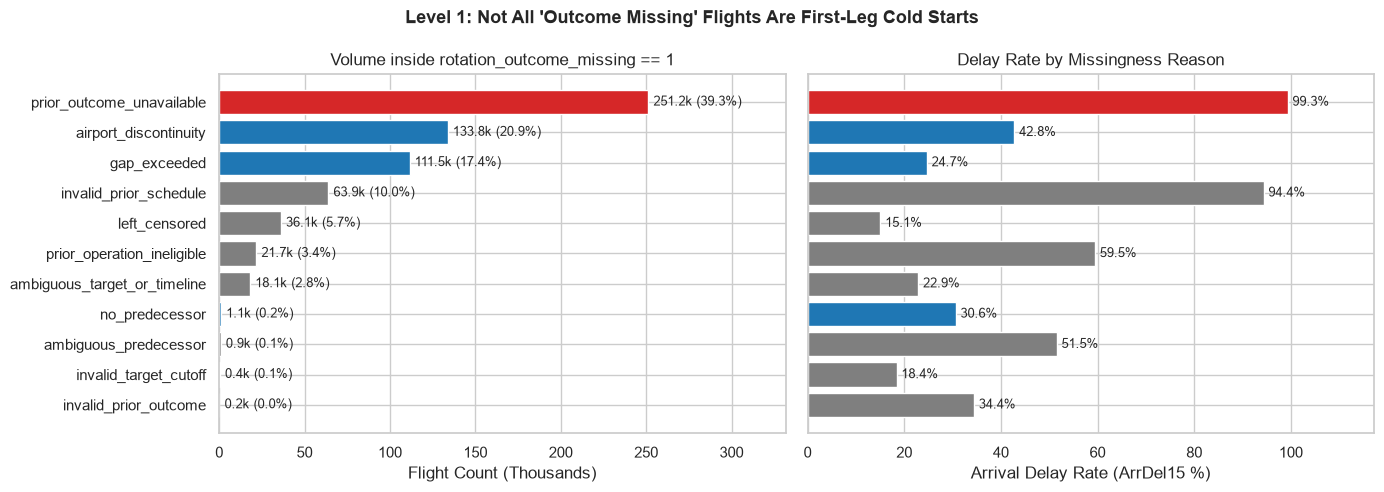

In [3]:
# 1A. Binary comparison: rotation_outcome_missing == 0 vs 1
binary_pd = (
    base_df.groupBy("rotation_outcome_missing")
    .agg(
        F.count("*").alias("flights"),
        F.sum("ArrDel15").alias("delayed_flights"),
        F.avg("ArrDel15").alias("delay_rate"),
        F.avg("ArrDelay").alias("mean_arr_delay_min"),
    )
    .orderBy("rotation_outcome_missing")
    .toPandas()
)
binary_pd["share_of_total"] = binary_pd["flights"] / binary_pd["flights"].sum()
binary_pd["label"] = binary_pd["rotation_outcome_missing"].map(
    {0: "0: Usable prior leg", 1: "1: Outcome missing"}
)
show_table(
    binary_pd[["label", "flights", "share_of_total", "delayed_flights", "delay_rate", "mean_arr_delay_min"]],
    {"flights": "{:,}", "delayed_flights": "{:,}", "share_of_total": "{:.2%}", "delay_rate": "{:.2%}", "mean_arr_delay_min": "{:.1f}"},
)

# 1B. Deconstruct rotation_outcome_missing == 1 by rotation_reason
reason_pd = (
    base_df.filter(F.col("rotation_outcome_missing") == 1)
    .groupBy("rotation_reason")
    .agg(
        F.count("*").alias("flights"),
        F.sum("ArrDel15").alias("delayed_flights"),
        F.avg("ArrDel15").alias("delay_rate"),
        F.avg("ArrDelay").alias("mean_arr_delay_min"),
        F.avg(F.when(F.col("ArrDel15") == 1, F.coalesce("LateAircraftDelay", F.lit(0.0)))).alias("mean_late_ac_min_when_delayed"),
    )
    .orderBy(F.desc("flights"))
    .toPandas()
)
reason_pd["share_of_missing"] = reason_pd["flights"] / reason_pd["flights"].sum()
reason_pd.to_csv(out_dir / "rotation_reason_overview.csv", index=False)

show_table(
    reason_pd,
    {
        "flights": "{:,}",
        "delayed_flights": "{:,}",
        "share_of_missing": "{:.2%}",
        "delay_rate": "{:.2%}",
        "mean_arr_delay_min": "{:.1f}",
        "mean_late_ac_min_when_delayed": "{:.1f}",
    },
)

# 1C. Cohort summary table (carrying clean cohorts into Levels 2-4)
cohort_pd = (
    base_df.groupBy("cohort")
    .agg(
        F.count("*").alias("flights"),
        F.sum("ArrDel15").alias("delayed_flights"),
        F.avg("ArrDel15").alias("delay_rate"),
        F.avg("ArrDelay").alias("mean_arr_delay_min"),
    )
    .orderBy(F.desc("flights"))
    .toPandas()
)
cohort_pd["share_of_total"] = cohort_pd["flights"] / cohort_pd["flights"].sum()
cohort_pd.to_csv(out_dir / "cohort_overview.csv", index=False)

# Plot Level 1: Reason breakdown (Volume vs. Delay Rate)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_df = reason_pd.sort_values("flights", ascending=True)
colors = ["#d62728" if r == "prior_outcome_unavailable" else ("#1f77b4" if r in TRUE_UNLINKED_REASONS else "#7f7f7f") for r in plot_df["rotation_reason"]]

axes[0].barh(plot_df["rotation_reason"], plot_df["flights"] / 1000.0, color=colors)
axes[0].set_xlabel("Flight Count (Thousands)")
axes[0].set_title("Volume inside rotation_outcome_missing == 1")
for i, v in enumerate(plot_df["flights"] / 1000.0):
    axes[0].text(v + 3, i, f"{v:,.1f}k ({plot_df['share_of_missing'].iloc[i]:.1%})", va="center", fontsize=9)
axes[0].set_xlim(0, (plot_df["flights"].max() / 1000.0) * 1.32)

axes[1].barh(plot_df["rotation_reason"], plot_df["delay_rate"] * 100.0, color=colors)
axes[1].set_xlabel("Arrival Delay Rate (ArrDel15 %)")
axes[1].set_title("Delay Rate by Missingness Reason")
for i, v in enumerate(plot_df["delay_rate"] * 100.0):
    axes[1].text(v + 1.0, i, f"{v:.1f}%", va="center", fontsize=9)
axes[1].set_xlim(0, max(plot_df["delay_rate"].max() * 100.0 * 1.18, 25))

fig.suptitle("Level 1: Not All 'Outcome Missing' Flights Are First-Leg Cold Starts", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### What Level 1 Just Revealed (Why This Matters)
Look at the red bar (`prior_outcome_unavailable`) vs. the blue bars (`gap_exceeded`, `airport_discontinuity`, `no_predecessor`):
- **`prior_outcome_unavailable` is hidden propagation, NOT a fresh start:** In [scripts/aircraft_rotation/build_features.py](../scripts/aircraft_rotation/build_features.py), `prior_outcome_unavailable` occurs when the aircraft **did** have a linked prior leg, but that inbound flight arrived **after** the current flight's scheduled departure time. Because we cannot leak a future arrival into pre-departure features, the pipeline marks `rotation_outcome_missing = 1`—which is why `rotation_outcome_missing` is the #1 predictor in Random Forest!
- **`true_unlinked` (`gap_exceeded` + `airport_discontinuity` + `no_predecessor`):** These flights genuinely have **no active inbound rotation delay** (the plane sat >24 hours, repositioned/came from an untracked flight, or had no prior BTS record).
- **Overnight first-of-day turns (<24h rest):** Note that an aircraft sitting overnight for 7–10 hours actually falls into `usable_clean` (`rotation_outcome_missing == 0` with `rotation_prior_arrival_delay_minutes <= 0`), so keeping `usable_clean` as our reference line lets us see whether `true_unlinked` flights behave like fresh morning aircraft or carry extra repositioning/schedule risk.

For the rest of the notebook, we examine **both** `true_unlinked` (pure root-delay cohort) and `all_outcome_missing` (`rotation_outcome_missing == 1`, matching Issue #13 literally).

---

## Level 2 (Intermediate): Official BTS Cause Attribution & Flight-Phase Breakdown

Now let's open the black box of delayed flights (`ArrDel15 == 1`). We ask two diagnostic questions:
1. **2A — Official BTS Cause Shares:** Across the 5 official DOT/BTS delay categories (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `SecurityDelay`, `LateAircraftDelay`), how much of the delay comes from **inbound propagation** vs. **airline operations**, **weather**, or **airspace/airport congestion (NAS)**?
   *(Note: BTS records cause minutes only on flights delayed 15+ minutes; if a flight has `ArrDel15 == 1` with all 5 cause columns null, we track it separately as `unattributed` rather than guessing.)*
2. **2B — Where in the Trip Does the Delay Happen?** Did the flight leave the gate late (`DepDelay`), lose time taxiing out on the tarmac (`TaxiOut`), or lose time in the air/arrival (`ArrDelay - DepDelay`)?

,cohort_group,delayed_flights,CarrierDelay_min_share,WeatherDelay_min_share,NASDelay_min_share,SecurityDelay_min_share,LateAircraftDelay_min_share
0,usable_clean,"391,677",49.3%,7.2%,37.3%,0.3%,5.9%
1,usable_late_inbound,"512,833",39.0%,6.6%,25.6%,0.2%,28.6%
2,prior_outcome_unavailable,"249,541",15.3%,4.1%,8.0%,0.1%,72.6%
3,true_unlinked,"85,085",41.9%,5.5%,8.9%,0.2%,43.5%
4,other_missing,"83,413",35.4%,6.1%,7.1%,0.1%,51.3%
5,all_outcome_missing,"418,039",26.0%,4.8%,8.0%,0.1%,61.1%


,cohort,ArrDel15,flights,median_dep_delay,mean_dep_delay,median_taxi_out,mean_taxi_out,median_airborne_delta,mean_airborne_delta
0,all_outcome_missing,0,"220,952",-3.0,-1.0,17.0,18.2,-9.0,-8.8
1,all_outcome_missing,1,"418,039",86.0,120.3,16.0,19.7,-6.0,-3.1
2,prior_outcome_unavailable,0,"1,709",29.0,22.5,14.0,15.1,-19.0,-18.8
3,prior_outcome_unavailable,1,"249,541",86.0,112.0,15.0,18.5,-7.0,-4.1
4,true_unlinked,0,"161,302",-3.0,-1.1,17.0,18.5,-8.0,-8.5
5,true_unlinked,1,"85,085",74.0,144.1,18.0,23.1,-3.0,1.2
6,usable_clean,0,"3,438,766",-4.0,-3.4,15.0,16.5,-8.0,-7.6
7,usable_clean,1,"391,677",24.0,41.4,20.0,25.8,8.0,11.1


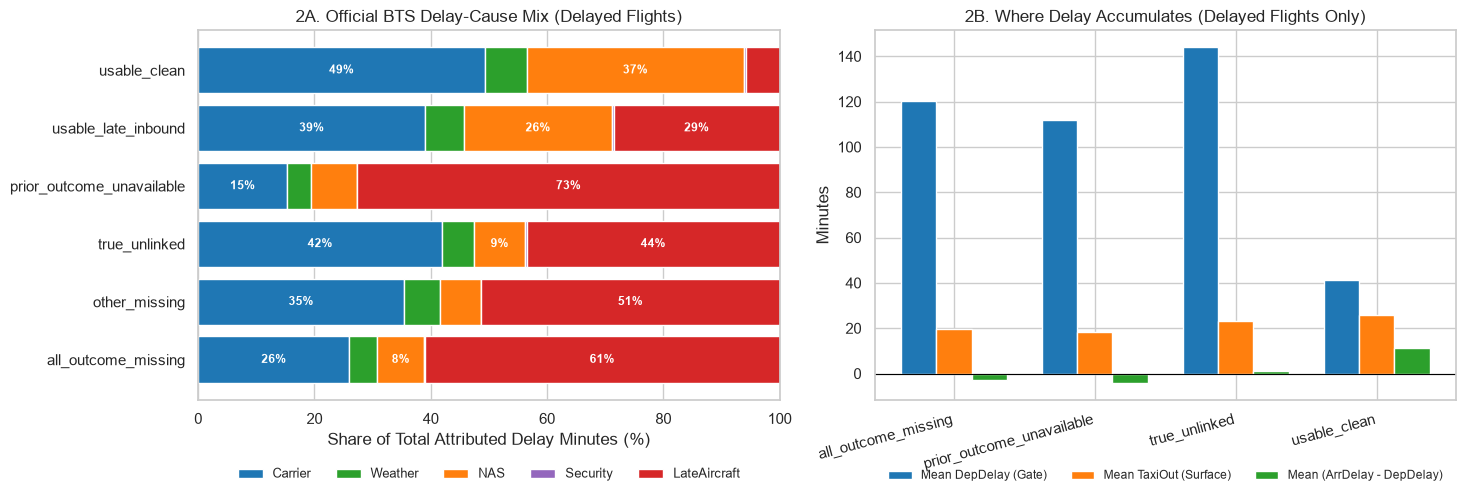

In [4]:
CAUSE_COLS = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]
has_any_cause = F.lit(False)
for c in CAUSE_COLS:
    has_any_cause = has_any_cause | F.col(c).isNotNull()

# Identify primary cause (largest single cause column when causes are reported).
delayed_df = base_df.filter(F.col("ArrDel15") == 1).withColumn("has_cause", has_any_cause)
for c in CAUSE_COLS:
    delayed_df = delayed_df.withColumn(f"_{c}", F.when(F.col("has_cause"), F.coalesce(F.col(c), F.lit(0.0))))

primary_expr = F.lit("Unattributed")
max_cause = F.greatest(*(F.col(f"_{c}") for c in CAUSE_COLS))
for c in CAUSE_COLS:
    primary_expr = F.when(F.col("has_cause") & (max_cause > 0) & (F.col(f"_{c}") == max_cause), c).otherwise(primary_expr)
delayed_df = delayed_df.withColumn("primary_cause", primary_expr)

def summarize_causes(frame, cohort_label_expr):
    return (
        frame.withColumn("cohort_group", cohort_label_expr)
        .groupBy("cohort_group")
        .agg(
            F.count("*").alias("delayed_flights"),
            F.sum(F.when(F.col("has_cause"), 1).otherwise(0)).alias("attributed_flights"),
            *[F.sum(f"_{c}").alias(f"{c}_min") for c in CAUSE_COLS],
            *[F.sum(F.when(F.col("primary_cause") == c, 1).otherwise(0)).alias(f"{c}_primary_cnt") for c in CAUSE_COLS],
        )
    )

causes_split = summarize_causes(delayed_df, F.col("cohort"))
causes_all_missing = summarize_causes(delayed_df.filter(F.col("rotation_outcome_missing") == 1), F.lit("all_outcome_missing"))
causes_pd = causes_split.unionByName(causes_all_missing).toPandas()

minute_cols = [f"{c}_min" for c in CAUSE_COLS]
causes_pd["total_cause_min"] = causes_pd[minute_cols].sum(axis=1)
for c in CAUSE_COLS:
    causes_pd[f"{c}_min_share"] = causes_pd[f"{c}_min"] / causes_pd["total_cause_min"].replace(0, np.nan)
    causes_pd[f"{c}_primary_share"] = causes_pd[f"{c}_primary_cnt"] / causes_pd["attributed_flights"].replace(0, np.nan)

order = ["usable_clean", "usable_late_inbound", "prior_outcome_unavailable", "true_unlinked", "other_missing", "all_outcome_missing"]
causes_pd["cohort_group"] = pd.Categorical(causes_pd["cohort_group"], categories=order, ordered=True)
causes_pd = causes_pd.sort_values("cohort_group").reset_index(drop=True)
causes_pd.to_csv(out_dir / "bts_causes_by_cohort.csv", index=False)

share_cols = ["cohort_group", "delayed_flights"] + [f"{c}_min_share" for c in CAUSE_COLS]
show_table(
    causes_pd[share_cols],
    {"delayed_flights": "{:,}", **{f"{c}_min_share": "{:.1%}" for c in CAUSE_COLS}},
)

# 2B. Flight-phase breakdown (Gate Departure vs TaxiOut vs Airborne/Arrival Delta)
phase_df = (
    base_df.withColumn("airborne_delta", F.col("ArrDelay") - F.col("DepDelay"))
    .filter(F.col("cohort").isin("usable_clean", "true_unlinked", "prior_outcome_unavailable"))
)
phase_split = (
    phase_df.groupBy("cohort", "ArrDel15")
    .agg(
        F.count("*").alias("flights"),
        F.expr("percentile_approx(DepDelay, 0.5)").alias("median_dep_delay"),
        F.avg("DepDelay").alias("mean_dep_delay"),
        F.expr("percentile_approx(TaxiOut, 0.5)").alias("median_taxi_out"),
        F.avg("TaxiOut").alias("mean_taxi_out"),
        F.expr("percentile_approx(airborne_delta, 0.5)").alias("median_airborne_delta"),
        F.avg("airborne_delta").alias("mean_airborne_delta"),
    )
)
phase_missing = (
    base_df.filter(F.col("rotation_outcome_missing") == 1)
    .withColumn("airborne_delta", F.col("ArrDelay") - F.col("DepDelay"))
    .groupBy(F.lit("all_outcome_missing").alias("cohort"), "ArrDel15")
    .agg(
        F.count("*").alias("flights"),
        F.expr("percentile_approx(DepDelay, 0.5)").alias("median_dep_delay"),
        F.avg("DepDelay").alias("mean_dep_delay"),
        F.expr("percentile_approx(TaxiOut, 0.5)").alias("median_taxi_out"),
        F.avg("TaxiOut").alias("mean_taxi_out"),
        F.expr("percentile_approx(airborne_delta, 0.5)").alias("median_airborne_delta"),
        F.avg("airborne_delta").alias("mean_airborne_delta"),
    )
)
phase_pd = phase_split.unionByName(phase_missing).orderBy("cohort", "ArrDel15").toPandas()
phase_pd.to_csv(out_dir / "phase_breakdown_by_cohort.csv", index=False)
show_table(
    phase_pd,
    {
        "flights": "{:,}",
        "median_dep_delay": "{:.1f}", "mean_dep_delay": "{:.1f}",
        "median_taxi_out": "{:.1f}", "mean_taxi_out": "{:.1f}",
        "median_airborne_delta": "{:.1f}", "mean_airborne_delta": "{:.1f}",
    },
)

# Plot Level 2: 100% stacked BTS cause shares + Phase decomposition
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

cause_colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#d62728"]
left = np.zeros(len(causes_pd))
y_labels = causes_pd["cohort_group"].astype(str)
for c, col in zip(CAUSE_COLS, cause_colors):
    vals = causes_pd[f"{c}_min_share"].fillna(0.0).to_numpy() * 100.0
    axes[0].barh(y_labels, vals, left=left, label=c.replace("Delay", ""), color=col)
    for idx, v in enumerate(vals):
        if v >= 8.0:
            axes[0].text(left[idx] + v / 2.0, idx, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
    left += vals
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Share of Total Attributed Delay Minutes (%)")
axes[0].set_title("2A. Official BTS Delay-Cause Mix (Delayed Flights)")
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False, fontsize=9)
axes[0].invert_yaxis()

delayed_phase = phase_pd[phase_pd["ArrDel15"] == 1].copy()
x = np.arange(len(delayed_phase))
w = 0.25
axes[1].bar(x - w, delayed_phase["mean_dep_delay"], width=w, label="Mean DepDelay (Gate)", color="#1f77b4")
axes[1].bar(x, delayed_phase["mean_taxi_out"], width=w, label="Mean TaxiOut (Surface)", color="#ff7f0e")
axes[1].bar(x + w, delayed_phase["mean_airborne_delta"], width=w, label="Mean (ArrDelay - DepDelay)", color="#2ca02c")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(delayed_phase["cohort"], rotation=15, ha="right")
axes[1].set_ylabel("Minutes")
axes[1].set_title("2B. Where Delay Accumulates (Delayed Flights Only)")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

---

## Level 3 (Intermediate-Advanced): Pre-Departure Risk Factors Inside Unlinked Flights

Level 2 uses post-flight BTS cause codes to explain *what happened*. Now we shift strictly to **pre-departure features** (what an airline or operations team can observe **before scheduled takeoff**) and compare **delayed (`ArrDel15 == 1`) vs. on-time (`ArrDel15 == 0`)** flights within **`true_unlinked`** (and **`all_outcome_missing`** alongside it).

We inspect four operational dimensions:
- **3A. Temporal, Carrier, and Airport Patterns:** Which hours, months, airlines, and origin hubs have the highest root-delay risk?
- **3B. Rolling Airport Congestion & Surface Traffic:** Do 2-hour rolling origin delays and taxi-out surges predict first-leg failures?
- **3C. Surface & En-Route Weather:** How strongly do ceiling, visibility, precipitation, thunderstorms, and SIGMETs drive root delays?
- **3D. Schedule Block-Time Slack:** Does padding scheduled block time (`outbound_schedule_slack_minutes`) absorb early operational friction?

,Reporting_Airline,true_unlinked_flights,true_unlinked_delay_rate,mean_carrier_min_delayed,mean_nas_min_delayed,mean_weather_min_delayed
0,OH,"6,136",48.92%,36.9,9.0,11.9
1,OO,"17,360",46.17%,135.6,9.4,22.9
2,MQ,"6,291",41.47%,19.2,11.7,12.2
3,AA,"52,083",40.11%,43.7,10.0,6.6
4,F9,"7,160",37.63%,60.7,12.1,5.5
5,WN,"25,224",36.96%,45.3,9.5,2.5
6,NK,"6,230",35.28%,63.0,35.8,3.7
7,DL,"30,754",32.28%,99.9,14.3,7.0
8,B6,"15,361",31.29%,75.4,15.6,2.3
9,9E,"7,445",29.58%,77.2,20.6,13.6


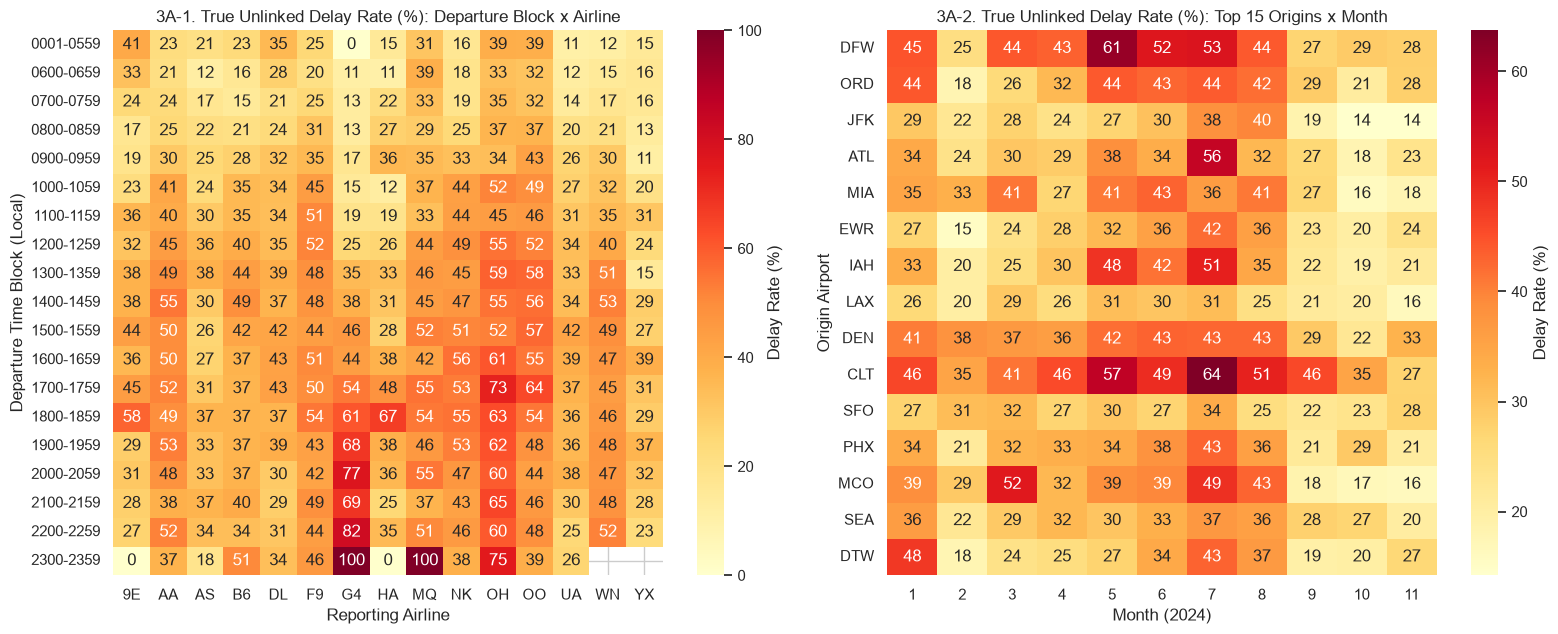

In [5]:
# 3A. Temporal, Carrier, and Airport slices on true_unlinked (plus all_outcome_missing reference)
unlinked_df = base_df.filter(F.col("cohort") == "true_unlinked")
missing_df = base_df.filter(F.col("rotation_outcome_missing") == 1)

carrier_hour_pd = (
    unlinked_df.groupBy("Reporting_Airline", "DepTimeBlk")
    .agg(
        F.count("*").alias("flights"),
        F.sum("ArrDel15").alias("delayed_flights"),
        F.avg("ArrDel15").alias("delay_rate"),
    )
    .toPandas()
)
carrier_hour_pd.to_csv(out_dir / "slice_carrier_hour.csv", index=False)

top15_origins = [r["Origin"] for r in unlinked_df.groupBy("Origin").count().orderBy(F.desc("count")).limit(15).collect()]
origin_month_pd = (
    unlinked_df.filter(F.col("Origin").isin(*top15_origins))
    .groupBy("Origin", "Month")
    .agg(
        F.count("*").alias("flights"),
        F.sum("ArrDel15").alias("delayed_flights"),
        F.avg("ArrDel15").alias("delay_rate"),
    )
    .toPandas()
)
origin_month_pd.to_csv(out_dir / "slice_origin_month.csv", index=False)

carrier_summary = (
    unlinked_df.groupBy("Reporting_Airline")
    .agg(
        F.count("*").alias("true_unlinked_flights"),
        F.avg("ArrDel15").alias("true_unlinked_delay_rate"),
        F.avg(F.when(F.col("ArrDel15") == 1, F.coalesce("CarrierDelay", F.lit(0.0)))).alias("mean_carrier_min_delayed"),
        F.avg(F.when(F.col("ArrDel15") == 1, F.coalesce("NASDelay", F.lit(0.0)))).alias("mean_nas_min_delayed"),
        F.avg(F.when(F.col("ArrDel15") == 1, F.coalesce("WeatherDelay", F.lit(0.0)))).alias("mean_weather_min_delayed"),
    )
    .orderBy(F.desc("true_unlinked_delay_rate"))
    .toPandas()
)
carrier_summary.to_csv(out_dir / "slice_carrier_summary.csv", index=False)
show_table(
    carrier_summary,
    {
        "true_unlinked_flights": "{:,}",
        "true_unlinked_delay_rate": "{:.2%}",
        "mean_carrier_min_delayed": "{:.1f}",
        "mean_nas_min_delayed": "{:.1f}",
        "mean_weather_min_delayed": "{:.1f}",
    },
)

# Heatmaps: DepTimeBlk x Reporting_Airline and Month x Top 15 Origin
pivot_ch = (carrier_hour_pd.pivot(index="DepTimeBlk", columns="Reporting_Airline", values="delay_rate") * 100.0).sort_index()
pivot_om = (origin_month_pd.pivot(index="Origin", columns="Month", values="delay_rate") * 100.0).reindex(top15_origins)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(pivot_ch, ax=axes[0], cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "Delay Rate (%)"})
axes[0].set_title("3A-1. True Unlinked Delay Rate (%): Departure Block x Airline")
axes[0].set_xlabel("Reporting Airline")
axes[0].set_ylabel("Departure Time Block (Local)")

sns.heatmap(pivot_om, ax=axes[1], cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "Delay Rate (%)"})
axes[1].set_title("3A-2. True Unlinked Delay Rate (%): Top 15 Origins x Month")
axes[1].set_xlabel("Month (2024)")
axes[1].set_ylabel("Origin Airport")

plt.tight_layout()
plt.show()

,feature,ontime_median,ontime_iqr,delayed_median,delayed_iqr,ontime_mean,delayed_mean,cohens_d
0,origin_departure_delay_rate_2h,0.11,0.18,0.22,0.30,0.15,0.28,+0.674
1,origin_departure_mean_delay_minutes_2h,6.52,13.18,14.10,22.83,11.67,23.24,+0.465
2,origin_departure_taxi_out_surge_2h,4.88,4.01,5.91,5.63,5.83,8.74,+0.422
3,destination_arrival_delay_rate_2h,0.11,0.23,0.18,0.27,0.17,0.25,+0.369
7,origin_precipitation_mm,0.00,0.00,0.00,0.00,0.06,0.21,+0.152
6,origin_wind_speed_ms,3.60,3.00,4.10,3.10,3.91,4.27,+0.150
11,Distance,864.00,769.00,781.00,728.00,1013.65,915.55,-0.141
5,origin_visibility_km,16.09,0.00,16.09,0.00,15.28,14.93,-0.119
10,outbound_schedule_slack_minutes,14.00,10.00,14.00,10.00,15.14,14.30,-0.093
8,destination_visibility_km,16.09,0.00,16.09,0.00,15.30,15.12,-0.064


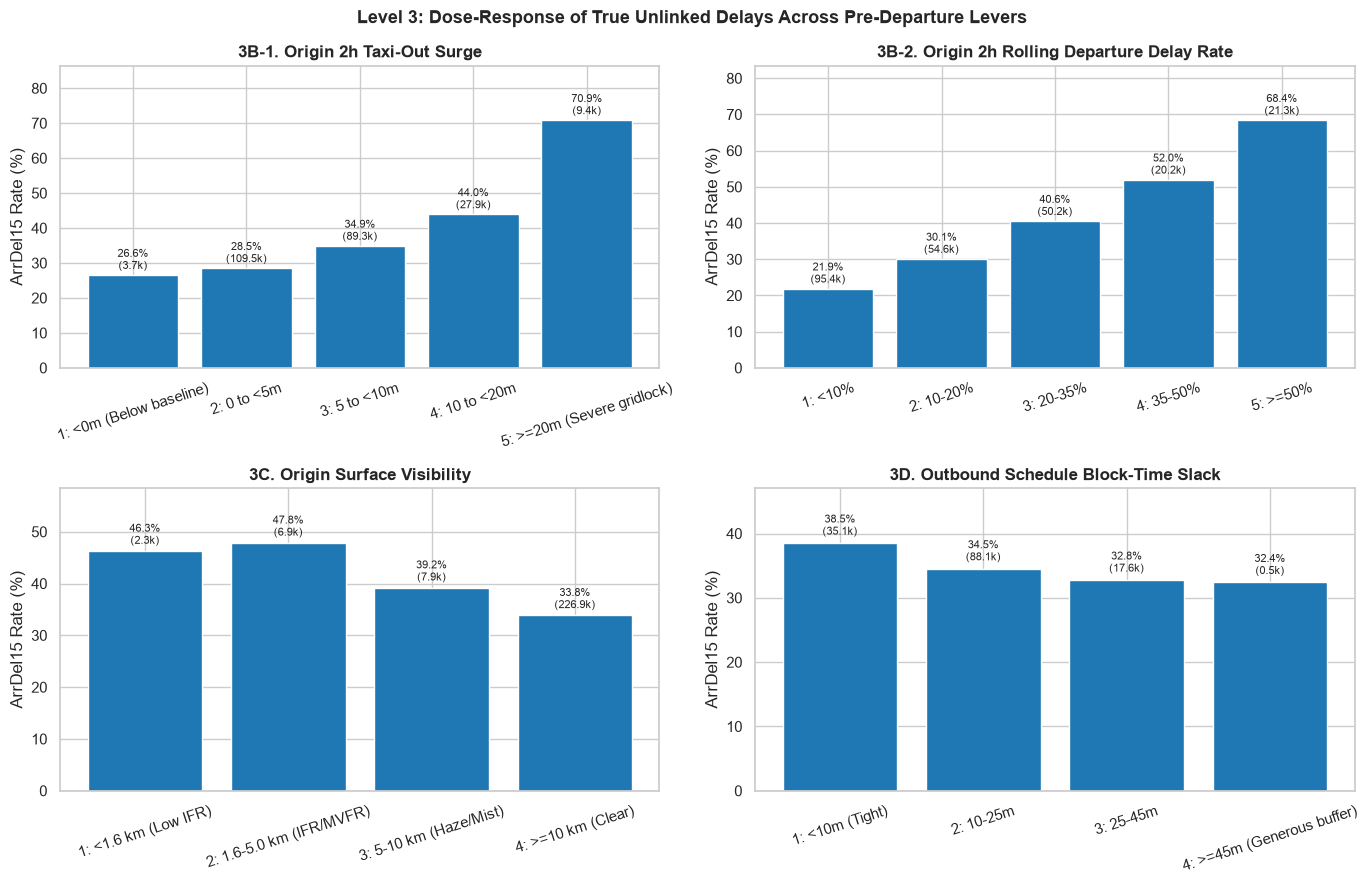

In [6]:
# 3B-3D. Continuous Pre-Departure Driver Comparison (Median, IQR, Mean, Cohen's d)
# At >100k rows, nearly any tiny shift has p < 0.001, so we emphasize standardized effect sizes (Cohen's d).
CONTINUOUS_FEATURES = [
    "origin_departure_delay_rate_2h",
    "origin_departure_mean_delay_minutes_2h",
    "origin_departure_taxi_out_surge_2h",
    "destination_arrival_delay_rate_2h",
    "origin_cloud_ceiling_m",
    "origin_visibility_km",
    "origin_wind_speed_ms",
    "origin_precipitation_mm",
    "destination_visibility_km",
    "dest_taf_ceiling_m",
    "outbound_schedule_slack_minutes",
    "Distance",
]

def compute_continuous_stats(df, cohort_name):
    aggs = []
    for col_name in CONTINUOUS_FEATURES:
        c = F.col(col_name)
        aggs.extend([
            F.count(c).alias(f"{col_name}__n"),
            F.avg(c).alias(f"{col_name}__mean"),
            F.stddev_samp(c).alias(f"{col_name}__std"),
            F.expr(f"percentile_approx({col_name}, 0.25)").alias(f"{col_name}__q25"),
            F.expr(f"percentile_approx({col_name}, 0.50)").alias(f"{col_name}__med"),
            F.expr(f"percentile_approx({col_name}, 0.75)").alias(f"{col_name}__q75"),
        ])
    grouped = df.groupBy("ArrDel15").agg(*aggs).collect()
    by_label = {int(r["ArrDel15"]): r.asDict() for r in grouped}
    rows = []
    for col_name in CONTINUOUS_FEATURES:
        d0, d1 = by_label[0], by_label[1]
        n0, n1 = d0[f"{col_name}__n"], d1[f"{col_name}__n"]
        m0, m1 = d0[f"{col_name}__mean"], d1[f"{col_name}__mean"]
        s0, s1 = d0[f"{col_name}__std"], d1[f"{col_name}__std"]
        if n0 and n1 and s0 is not None and s1 is not None:
            pooled = np.sqrt(((n0 - 1) * (s0 ** 2) + (n1 - 1) * (s1 ** 2)) / max(n0 + n1 - 2, 1))
            cohens_d = (m1 - m0) / pooled if pooled > 0 else 0.0
        else:
            cohens_d = np.nan
        rows.append({
            "cohort": cohort_name,
            "feature": col_name,
            "ontime_median": d0[f"{col_name}__med"],
            "ontime_iqr": (d0[f"{col_name}__q75"] - d0[f"{col_name}__q25"]) if d0[f"{col_name}__q75"] is not None else np.nan,
            "delayed_median": d1[f"{col_name}__med"],
            "delayed_iqr": (d1[f"{col_name}__q75"] - d1[f"{col_name}__q25"]) if d1[f"{col_name}__q75"] is not None else np.nan,
            "ontime_mean": m0,
            "delayed_mean": m1,
            "cohens_d": cohens_d,
            "abs_cohens_d": abs(cohens_d) if pd.notna(cohens_d) else np.nan,
        })
    return pd.DataFrame(rows)

cont_pd = pd.concat([
    compute_continuous_stats(unlinked_df, "true_unlinked"),
    compute_continuous_stats(missing_df, "all_outcome_missing"),
], ignore_index=True)
cont_pd.to_csv(out_dir / "continuous_driver_stats.csv", index=False)

show_table(
    cont_pd[cont_pd["cohort"] == "true_unlinked"]
    .sort_values("abs_cohens_d", ascending=False)
    .drop(columns=["cohort", "abs_cohens_d"]),
    {
        "ontime_median": "{:.2f}", "ontime_iqr": "{:.2f}",
        "delayed_median": "{:.2f}", "delayed_iqr": "{:.2f}",
        "ontime_mean": "{:.2f}", "delayed_mean": "{:.2f}",
        "cohens_d": "{:+.3f}",
    },
)

# Binned dose-response curves for 4 key operational levers inside true_unlinked
binned_specs = [
    (
        "origin_departure_taxi_out_surge_2h",
        F.when(F.col("origin_departure_taxi_out_surge_2h").isNull(), "Missing")
        .when(F.col("origin_departure_taxi_out_surge_2h") < 0, "1: <0m (Below baseline)")
        .when(F.col("origin_departure_taxi_out_surge_2h") < 5, "2: 0 to <5m")
        .when(F.col("origin_departure_taxi_out_surge_2h") < 10, "3: 5 to <10m")
        .when(F.col("origin_departure_taxi_out_surge_2h") < 20, "4: 10 to <20m")
        .otherwise("5: >=20m (Severe gridlock)"),
    ),
    (
        "origin_departure_delay_rate_2h",
        F.when(F.col("origin_departure_delay_rate_2h").isNull(), "Missing")
        .when(F.col("origin_departure_delay_rate_2h") < 0.10, "1: <10%")
        .when(F.col("origin_departure_delay_rate_2h") < 0.20, "2: 10-20%")
        .when(F.col("origin_departure_delay_rate_2h") < 0.35, "3: 20-35%")
        .when(F.col("origin_departure_delay_rate_2h") < 0.50, "4: 35-50%")
        .otherwise("5: >=50%"),
    ),
    (
        "origin_visibility_km",
        F.when(F.col("origin_visibility_km").isNull(), "Missing")
        .when(F.col("origin_visibility_km") < 1.6, "1: <1.6 km (Low IFR)")
        .when(F.col("origin_visibility_km") < 5.0, "2: 1.6-5.0 km (IFR/MVFR)")
        .when(F.col("origin_visibility_km") < 10.0, "3: 5-10 km (Haze/Mist)")
        .otherwise("4: >=10 km (Clear)"),
    ),
    (
        "outbound_schedule_slack_minutes",
        F.when(F.col("outbound_schedule_slack_minutes").isNull(), "Missing")
        .when(F.col("outbound_schedule_slack_minutes") < 10, "1: <10m (Tight)")
        .when(F.col("outbound_schedule_slack_minutes") < 25, "2: 10-25m")
        .when(F.col("outbound_schedule_slack_minutes") < 45, "3: 25-45m")
        .otherwise("4: >=45m (Generous buffer)"),
    ),
]

dose_frames = []
for feat, bin_expr in binned_specs:
    agg_pd = (
        unlinked_df.withColumn("bin", bin_expr)
        .filter(F.col("bin") != "Missing")
        .groupBy("bin")
        .agg(F.count("*").alias("flights"), F.avg("ArrDel15").alias("delay_rate"))
        .orderBy("bin")
        .toPandas()
    )
    agg_pd["feature"] = feat
    dose_frames.append(agg_pd)

dose_pd = pd.concat(dose_frames, ignore_index=True)
dose_pd.to_csv(out_dir / "binned_dose_response.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
titles = {
    "origin_departure_taxi_out_surge_2h": "3B-1. Origin 2h Taxi-Out Surge",
    "origin_departure_delay_rate_2h": "3B-2. Origin 2h Rolling Departure Delay Rate",
    "origin_visibility_km": "3C. Origin Surface Visibility",
    "outbound_schedule_slack_minutes": "3D. Outbound Schedule Block-Time Slack",
}
for ax, (feat, _) in zip(axes.flat, binned_specs):
    sub = dose_pd[dose_pd["feature"] == feat]
    bars = ax.bar(sub["bin"], sub["delay_rate"] * 100.0, color="#1f77b4")
    ax.set_title(titles[feat], fontweight="bold")
    ax.set_ylabel("ArrDel15 Rate (%)")
    ax.tick_params(axis="x", rotation=18)
    ax.set_ylim(0, max(sub["delay_rate"].max() * 100.0 * 1.22, 15))
    for bar, (_, row) in zip(bars, sub.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            bar.get_height() + 0.8,
            f"{row['delay_rate']*100:.1f}%\n({row['flights']/1000:.1f}k)",
            ha="center", va="bottom", fontsize=8,
        )

fig.suptitle("Level 3: Dose-Response of True Unlinked Delays Across Pre-Departure Levers", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---

## Level 4 (Synthesis): The Trigger Matrix (Severity vs. Prevalence)

A single chart often trips people up in root-cause analysis: **rare severe events** (like thunderstorms or freezing rain) have dramatic delay multipliers, while **everyday operational conditions** (like elevated taxi-out surge or peak-hour congestion) happen far more often and can account for **more total delayed flights**.

Below, we place binary weather, en-route, holiday, and high-congestion triggers on a **Trigger Matrix**:
- **Y-axis — Relative Risk:** How much more likely is `ArrDel15 == 1` when the trigger is active vs. inactive?
- **X-axis — Prevalence:** What % of `true_unlinked` flights experience the trigger?
- **Bubble Size & Table — Excess Delayed Flights:** Approximately how many additional delayed flights occur under that trigger compared to its baseline rate: $\text{flights}_{X=1} \times (P(\text{delay}|X=1) - P(\text{delay}|X=0))$.

,trigger,flights_active,prevalence,rate_when_active,rate_when_inactive,relative_risk,excess_delayed_flights
0,origin_weather_freezing,313,0.13%,83.07%,34.47%,2.41x,152
1,origin_weather_thunderstorm,"2,604",1.06%,80.18%,34.05%,2.36x,"1,201"
2,origin_weather_snow,"2,616",1.06%,69.53%,34.16%,2.04x,925
3,high_origin_delay_2h (>=30%),"54,382",22.07%,56.79%,28.23%,2.01x,"15,534"
4,destination_weather_thunderstorm,"2,360",0.96%,64.24%,34.25%,1.88x,708
5,dest_taf_thunderstorm,"8,553",3.47%,56.09%,33.76%,1.66x,"1,910"
6,high_taxi_surge_2h (>=10m),"37,244",15.12%,50.72%,31.65%,1.60x,"7,104"
7,enroute_sigmet_corridor_blocked,"110,368",44.79%,41.51%,28.87%,1.44x,"13,951"
8,origin_weather_rain,"14,622",5.93%,47.46%,33.72%,1.41x,"2,009"
9,dest_taf_is_ifr,"11,589",4.70%,39.51%,34.29%,1.15x,605


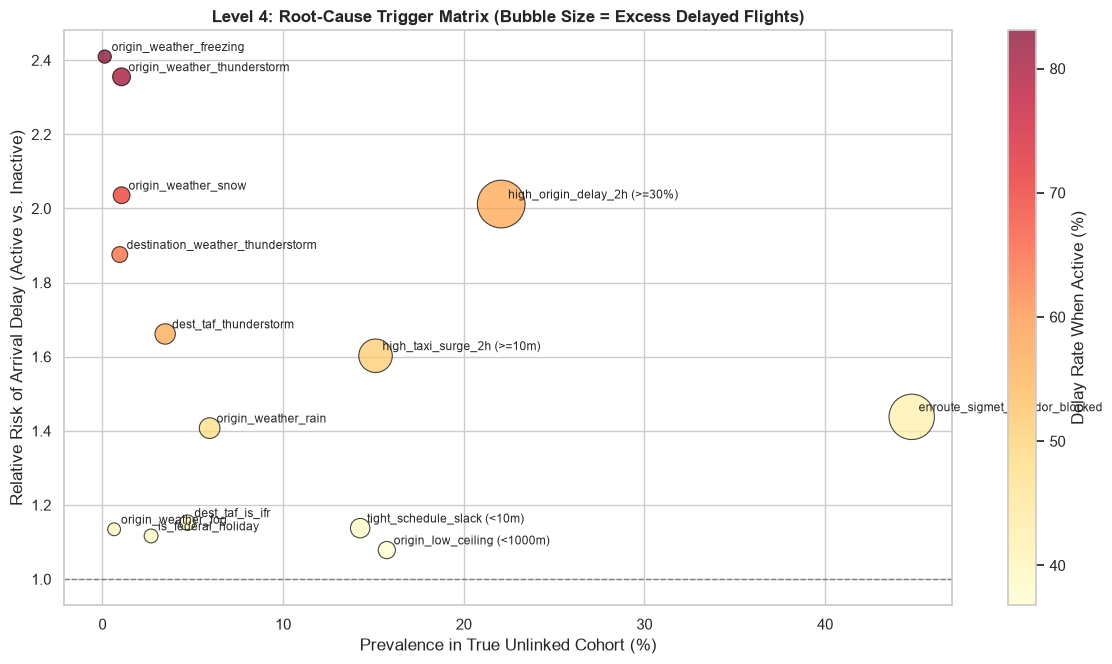

Spark session stopped; all summary tables exported to results/root_cause/.


In [7]:
TRIGGERS = [
    ("origin_weather_thunderstorm", (F.col("origin_weather_thunderstorm") == 1)),
    ("origin_weather_freezing", (F.col("origin_weather_freezing") == 1)),
    ("origin_weather_snow", (F.col("origin_weather_snow") == 1)),
    ("origin_weather_fog", (F.col("origin_weather_fog") == 1)),
    ("origin_weather_rain", (F.col("origin_weather_rain") == 1)),
    ("origin_low_ceiling (<1000m)", F.col("origin_cloud_ceiling_m").isNotNull() & (F.col("origin_cloud_ceiling_m") < 1000)),
    ("destination_weather_thunderstorm", (F.col("destination_weather_thunderstorm") == 1)),
    ("dest_taf_is_ifr", (F.col("dest_taf_is_ifr") == 1)),
    ("dest_taf_thunderstorm", (F.col("dest_taf_thunderstorm") == 1)),
    ("enroute_sigmet_corridor_blocked", (F.col("enroute_sigmet_corridor_blocked") == 1)),
    ("is_federal_holiday", (F.col("is_federal_holiday") == 1)),
    ("high_origin_delay_2h (>=30%)", F.col("origin_departure_delay_rate_2h") >= 0.30),
    ("high_taxi_surge_2h (>=10m)", F.col("origin_departure_taxi_out_surge_2h") >= 10.0),
    ("tight_schedule_slack (<10m)", F.col("outbound_schedule_slack_minutes") < 10.0),
]

aggs = [F.count("*").alias("total_n")]
for idx, (_, cond) in enumerate(TRIGGERS):
    c = F.coalesce(cond, F.lit(False))
    aggs.extend([
        F.sum(F.when(c, 1).otherwise(0)).alias(f"n1_{idx}"),
        F.sum(F.when(c & (F.col("ArrDel15") == 1), 1).otherwise(0)).alias(f"d1_{idx}"),
        F.sum(F.when(~c, 1).otherwise(0)).alias(f"n0_{idx}"),
        F.sum(F.when(~c & (F.col("ArrDel15") == 1), 1).otherwise(0)).alias(f"d0_{idx}"),
    ])

stats_row = unlinked_df.agg(*aggs).first().asDict()
total_n = stats_row["total_n"]

trigger_rows = []
for idx, (name, _) in enumerate(TRIGGERS):
    n1, d1 = stats_row[f"n1_{idx}"], stats_row[f"d1_{idx}"]
    n0, d0 = stats_row[f"n0_{idx}"], stats_row[f"d0_{idx}"]
    r1 = d1 / n1 if n1 else np.nan
    r0 = d0 / n0 if n0 else np.nan
    rr = r1 / r0 if (n1 and n0 and r0 > 0) else np.nan
    excess = n1 * (r1 - r0) if (n1 and n0) else 0.0
    trigger_rows.append({
        "trigger": name,
        "flights_active": n1,
        "prevalence": n1 / total_n,
        "rate_when_active": r1,
        "rate_when_inactive": r0,
        "relative_risk": rr,
        "excess_delayed_flights": excess,
    })

trigger_pd = pd.DataFrame(trigger_rows).sort_values("relative_risk", ascending=False).reset_index(drop=True)
trigger_pd.to_csv(out_dir / "trigger_matrix.csv", index=False)

show_table(
    trigger_pd,
    {
        "flights_active": "{:,}",
        "prevalence": "{:.2%}",
        "rate_when_active": "{:.2%}",
        "rate_when_inactive": "{:.2%}",
        "relative_risk": "{:.2f}x",
        "excess_delayed_flights": "{:,.0f}",
    },
)

# Plot Trigger Matrix
fig, ax = plt.subplots(figsize=(12, 6.8))
pos_excess = np.clip(trigger_pd["excess_delayed_flights"].fillna(0), 0, None)
sizes = 80.0 + 1100.0 * (pos_excess / max(float(pos_excess.max()), 1.0))
scatter = ax.scatter(
    trigger_pd["prevalence"] * 100.0,
    trigger_pd["relative_risk"],
    s=sizes,
    alpha=0.72,
    c=trigger_pd["rate_when_active"] * 100.0,
    cmap="YlOrRd",
    edgecolors="black",
    linewidth=0.8,
)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Delay Rate When Active (%)")

for _, row in trigger_pd.iterrows():
    ax.annotate(
        row["trigger"],
        (row["prevalence"] * 100.0, row["relative_risk"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8.5,
    )

ax.axhline(1.0, color="gray", linestyle="--", linewidth=1.0)
ax.set_xlabel("Prevalence in True Unlinked Cohort (%)")
ax.set_ylabel("Relative Risk of Arrival Delay (Active vs. Inactive)")
ax.set_title("Level 4: Root-Cause Trigger Matrix (Bubble Size = Excess Delayed Flights)", fontweight="bold")
plt.tight_layout()
plt.show()

# Free Spark cache and stop Spark cleanly after all aggregations are saved.
base_df.unpersist(blocking=True)
spark.stop()
print("Spark session stopped; all summary tables exported to results/root_cause/.")

---

## Key Takeaways (Plain-English Summary for Issue #13)

Run the summary cell below to print a concise, data-driven synthesis directly from the exported tables in `results/root_cause/`.

In [8]:
# Print a concise plain-English digest directly from the saved CSVs.
cohort_sum = pd.read_csv(out_dir / "cohort_overview.csv").set_index("cohort")
causes_sum = pd.read_csv(out_dir / "bts_causes_by_cohort.csv").set_index("cohort_group")
triggers_sum = pd.read_csv(out_dir / "trigger_matrix.csv")

total_flights = int(cohort_sum["flights"].sum())
tu_row = cohort_sum.loc["true_unlinked"]
pou_row = cohort_sum.loc["prior_outcome_unavailable"]
uc_row = cohort_sum.loc["usable_clean"]

print("=== EXECUTIVE SUMMARY: ROOT CAUSES OF FIRST-LEG / UNLINKED DELAYS ===")
print(f"1. Cohort Size (Train+Val): {total_flights:,} flights total.")
print(
    f"2. Why 'rotation_outcome_missing == 1' is misleading if unstratified: "
    f"prior_outcome_unavailable ({int(pou_row['flights']):,} flights) has a {pou_row['delay_rate']:.1%} delay rate "
    f"(mostly LateAircraft propagation), vs. true_unlinked ({int(tu_row['flights']):,} flights) at {tu_row['delay_rate']:.1%} "
    f"and usable_clean ({int(uc_row['flights']):,} flights) at {uc_row['delay_rate']:.1%}."
)

tu_causes = causes_sum.loc["true_unlinked"]
print(
    "3. Official BTS Causes on Delayed True-Unlinked Flights: "
    f"Carrier={tu_causes['CarrierDelay_min_share']:.1%}, "
    f"NAS={tu_causes['NASDelay_min_share']:.1%}, "
    f"LateAircraft={tu_causes['LateAircraftDelay_min_share']:.1%}, "
    f"Weather={tu_causes['WeatherDelay_min_share']:.1%}, "
    f"Security={tu_causes['SecurityDelay_min_share']:.1%}."
)

top_rr = triggers_sum.sort_values("relative_risk", ascending=False).head(3)
top_vol = triggers_sum.sort_values("excess_delayed_flights", ascending=False).head(3)
print("4. Highest-Severity Triggers (Relative Risk):")
for _, r in top_rr.iterrows():
    print(f"   - {r['trigger']}: {r['relative_risk']:.2f}x risk ({r['rate_when_active']:.1%} delay rate, {r['prevalence']:.2%} prevalence)")
print("5. Largest-Volume Triggers (Excess Delayed Flights):")
for _, r in top_vol.iterrows():
    print(f"   - {r['trigger']}: +{r['excess_delayed_flights']:,.0f} excess delayed flights ({r['relative_risk']:.2f}x risk, {r['prevalence']:.2%} prevalence)")

=== EXECUTIVE SUMMARY: ROOT CAUSES OF FIRST-LEG / UNLINKED DELAYS ===
1. Cohort Size (Train+Val): 6,355,884 flights total.
2. Why 'rotation_outcome_missing == 1' is misleading if unstratified: prior_outcome_unavailable (251,250 flights) has a 99.3% delay rate (mostly LateAircraft propagation), vs. true_unlinked (246,387 flights) at 34.5% and usable_clean (3,830,443 flights) at 10.2%.
3. Official BTS Causes on Delayed True-Unlinked Flights: Carrier=41.9%, NAS=8.9%, LateAircraft=43.5%, Weather=5.5%, Security=0.2%.
4. Highest-Severity Triggers (Relative Risk):
   - origin_weather_freezing: 2.41x risk (83.1% delay rate, 0.13% prevalence)
   - origin_weather_thunderstorm: 2.36x risk (80.2% delay rate, 1.06% prevalence)
   - origin_weather_snow: 2.04x risk (69.5% delay rate, 1.06% prevalence)
5. Largest-Volume Triggers (Excess Delayed Flights):
   - high_origin_delay_2h (>=30%): +15,534 excess delayed flights (2.01x risk, 22.07% prevalence)
   - enroute_sigmet_corridor_blocked: +13,951 exces